In [ ]:
import numpy as np
import matplotlib.pyplot as plt

Ejercicio 1

In [ ]:
# Integrador rk4 e integrador ode
def rk4(f, x, t, h, p):
    k1 = f(x, t, p)
    k2 = f(x + 0.5*h*k1, t + 0.5*h, p)
    k3 = f(x + 0.5*h*k2, t + 0.5*h, p)
    k4 = f(x + h*k3, t + h, p)
    return x + h*(k1 + 2.0*k2 + 2.0*k3 + k4)/6.0

def integrador_ode(m, f, xa, a, b, k, p, c=lambda x, t, p: x):
    assert k > 0
    n = len(xa)
    h = (b - a)/k
    w = np.zeros((n, k + 1))
    t = np.zeros(k + 1)
    w[:, 0] = xa
    t[0] = a
    for j in range(k):
        t[j + 1] = t[j] + h
        w[:, j + 1] = m(f, w[:, j], t[j], h, p)   # paso de RK4
        w[:, j + 1] = c(w[:, j + 1], t[j + 1], p) # reseteo si v >= 30
    return t, w

# Modelo de Izhikevich
def I_escalon(t):
    return 10 if t >= 10 else 0

def f_izhikevich(x, t, p):
    v, u = x
    dv = p['g2']*v**2 + p['g1']*v + p['g0'] - u + p['I'](t)   # Ec. (1)
    du = p['a']*(p['b']*v - u)                                # Ec. (2)
    return np.array([dv, du])

def reset_izhikevich(x, t, p):
    v, u = x
    if v >= p['v_pico']:        # 30 mV: valor para registrar el spike, no umbral fisiológico
        p['spikes'].append(t)   # registra el tiempo de disparo
        v = p['c']              # v <- c
        u = u + p['d']          # u <- u + d
    return np.array([v, u])

# Parámetros del punto 1)
p = {'g2': 0.04, 'g1': 5.0, 'g0': 140.0,
     'a': 0.02, 'b': 0.2, 'c': -65.0, 'd': 2.0,
     'v_pico': 30.0, 'I': I_escalon, 'spikes': []}

# Condiciones iniciales
v0 = -70.0
x0 = np.array([v0, p['b']*v0])      # u(0) = b v(0) = -14

# Integración: t en [0, 100], h = 0.1  ->  k = 1000 pasos
p['spikes'] = []                    # vaciar antes de cada simulación
t, w = integrador_ode(rk4, f_izhikevich, x0, a=0.0, b=100.0, k=1000, p=p, c=reset_izhikevich)

print("Número de spikes:", len(p['spikes']))
print("Tiempos de disparo (ms):", np.round(p['spikes'], 1))

Número de spikes: 7
Tiempos de disparo (ms): [13.5 17.1 21.9 29.5 44.7 63.7 82.6]


Ejercicio 2

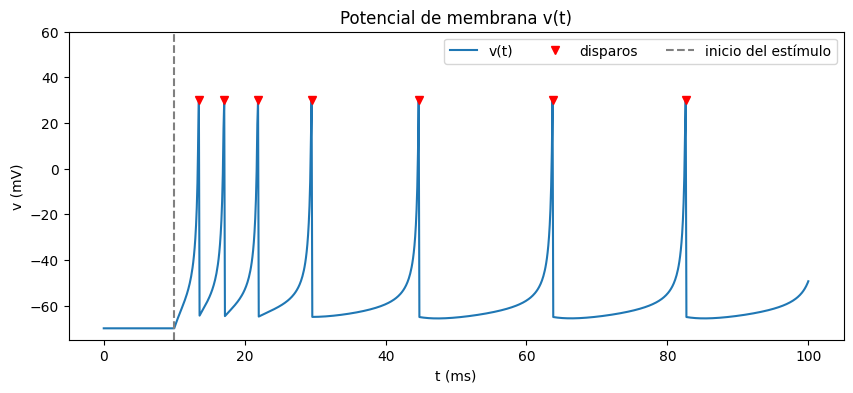

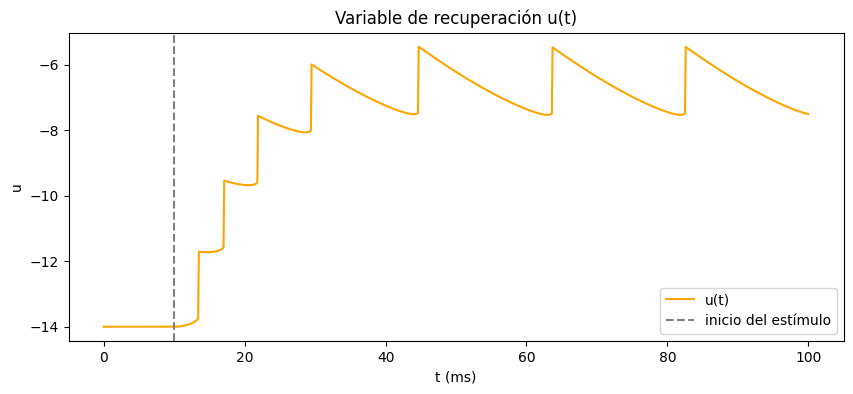

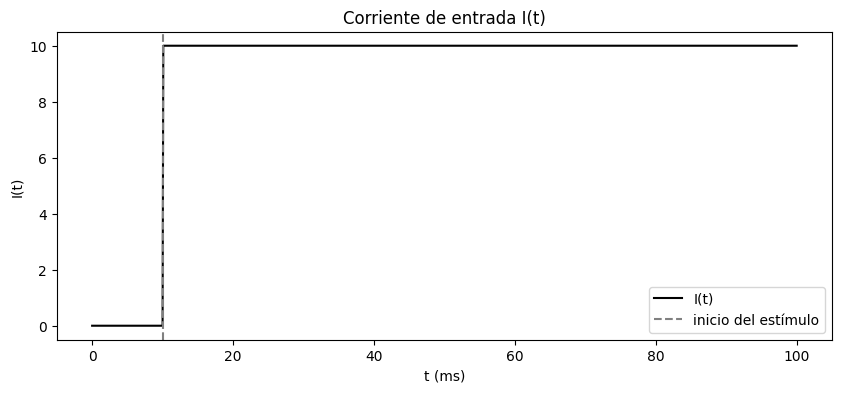

In [ ]:
# Graficos v(t), u(t), I(t)
t_estimulo = 10.0
spikes = np.array(p['spikes']) # Lista de tiempos de disparo

v_graf = w[0, :].copy() # Copia de v solo para graficar
# Posición (índice) de cada spike = tiempo / h; se redondea y se pasa a entero
# En esas posiciones se pone 30, para que el gráfico muestre el pico completo
v_graf[np.rint(spikes / (t[1] - t[0])).astype(int)] = 30.0

# Figura 1: potencial de membrana, con los disparos marcados
plt.figure(figsize=(10, 4))
plt.plot(t, v_graf, label='v(t)')
plt.plot(spikes, np.full(len(spikes), 30.0), 'rv', label='disparos')
plt.axvline(t_estimulo, color='gray', ls='--', label='inicio del estímulo')
plt.xlabel('t (ms)')
plt.ylabel('v (mV)')
plt.title('Potencial de membrana v(t)')
plt.ylim(-75, 60)
plt.legend(loc='upper right', ncol=3)
plt.show()

# Figura 2: variable de recuperación
plt.figure(figsize=(10, 4))
plt.plot(t, w[1, :], color='orange', label='u(t)')
plt.axvline(t_estimulo, color='gray', ls='--', label='inicio del estímulo')
plt.xlabel('t (ms)')
plt.ylabel('u')
plt.title('Variable de recuperación u(t)')
plt.legend()
plt.show()

# Figura 3: corriente de entrada
plt.figure(figsize=(10, 4))
plt.plot(t, [p['I'](ti) for ti in t], color='k', label='I(t)')
plt.axvline(t_estimulo, color='gray', ls='--', label='inicio del estímulo')
plt.xlabel('t (ms)')
plt.ylabel('I(t)')
plt.title('Corriente de entrada I(t)')
plt.legend()
plt.show()

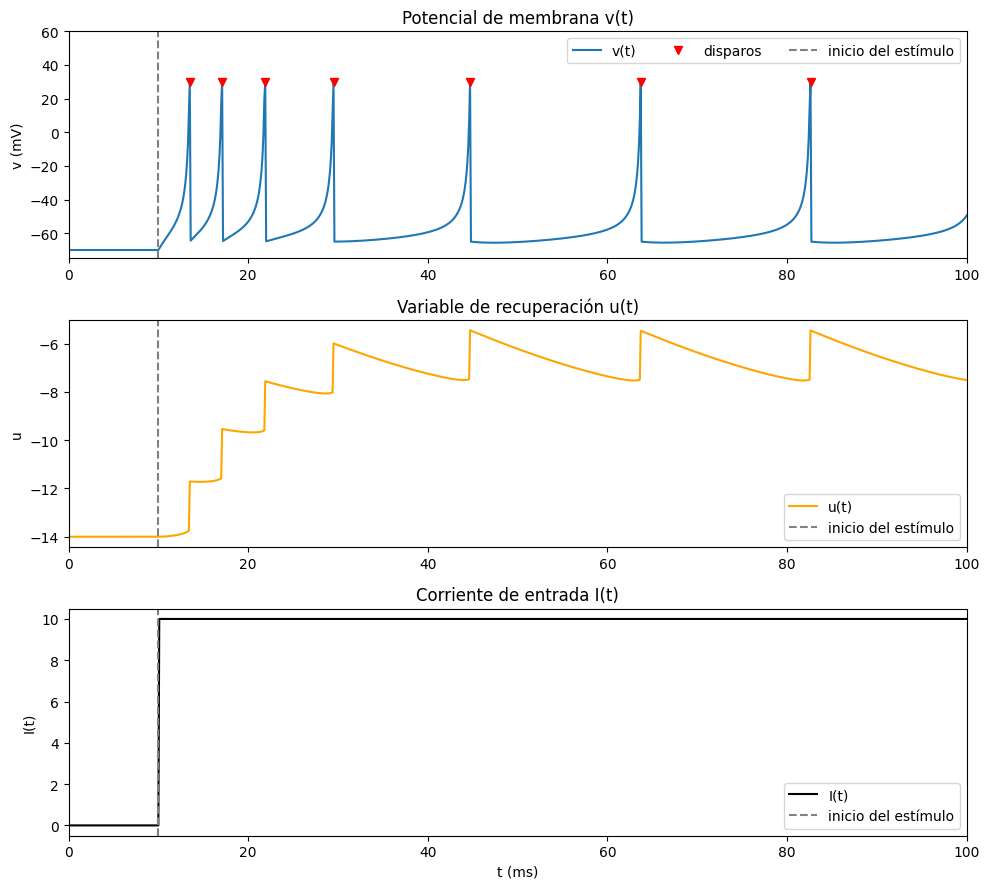

In [ ]:
# Graficos v(t), u(t), I(t)
t_estimulo = 10.0
spikes = np.array(p['spikes']) # Lista de tiempos de disparo

v_graf = w[0, :].copy() # Copia de v solo para graficar
# Posición (índice) de cada spike = tiempo / h; se redondea y se pasa a entero
# En esas posiciones se pone 30, para que el gráfico muestre el pico completo
v_graf[np.rint(spikes / (t[1] - t[0])).astype(int)] = 30.0

plt.figure(figsize=(10, 9))

# Potencial de membrana con los disparos marcados
plt.subplot(3, 1, 1)
plt.plot(t, v_graf, label='v(t)')
plt.plot(spikes, np.full(len(spikes), 30.0), 'rv', label='disparos')
plt.axvline(t_estimulo, color='gray', ls='--', label='inicio del estímulo')
plt.xlim(t[0], t[-1])
plt.ylabel('v (mV)')
plt.title('Potencial de membrana v(t)')
plt.ylim(-75, 60)
plt.legend(loc='upper right', ncol=3)

# Variable de recuperación
plt.subplot(3, 1, 2)
plt.plot(t, w[1, :], color='orange', label='u(t)')
plt.axvline(t_estimulo, color='gray', ls='--', label='inicio del estímulo')
plt.xlim(t[0], t[-1])
plt.ylabel('u')
plt.title('Variable de recuperación u(t)')
plt.legend()

# Corriente de entrada
plt.subplot(3, 1, 3)
plt.plot(t, [p['I'](ti) for ti in t], color='k', label='I(t)')
plt.axvline(t_estimulo, color='gray', ls='--', label='inicio del estímulo')
plt.xlim(t[0], t[-1])
plt.xlabel('t (ms)')
plt.ylabel('I(t)')
plt.title('Corriente de entrada I(t)')
plt.legend()

plt.tight_layout()
plt.show()

Ejercicio 3

In [ ]:
def rk4(f, x, t, h, p):
  k1 = f(x, t, p)
  k2 = f(x + 0.5*h*k1, t + 0.5*h, p)
  k3 = f(x + 0.5*h*k2, t + 0.5*h, p)
  k4 = f(x + h*k3, t + h, p)
  return x + h*(k1 + 2.0*k2 + 2.0*k3 + k4)/6.0

def integrador_ode(m, f, xa, a, b, k, p, c=lambda x, t, p: x):
  assert k > 0
  n = len(xa)
  h = (b - a)/k
  w = np.zeros((n, k + 1))
  t = np.zeros(k + 1)
  w[:, 0] = xa
  t[0] = a
  for j in range(k):
    t[j + 1] = t[j] + h
    w[:, j + 1] = m(f, w[:, j], t[j], h, p)   # paso de RK4
    w[:, j + 1] = c(w[:, j + 1], t[j + 1], p) # reseteo si v >= 30
  return t, w

# Modelo de Izhikevich

def f_izhikevich(x, t, p):
  v, u = x
  dv = p['g2']*v**2 + p['g1']*v + p['g0'] - u + p['I'](t)   # Ec. (1)
  du = p['a']*(p['b']*v - u)                                # Ec. (2)
  return np.array([dv, du])

def reset_izhikevich(x, t, p):
  v, u = x
  if v >= p['v_pico']:      # 30 mV: valor para registrar el spike, no umbral fisiológico
    p['spikes'].append(t)   # registra el tiempo de disparo
    v = p['c']              # v <- c
    u = u + p['d']          # u <- u + d
  return np.array([v, u])

In [ ]:
# Regular Spiking

def I_escalon(t):
  return 10 if t >= 20 else 0

# Parámetros RS: a=0.02, b=0.2, c=-65, d=8
p = { 'g2': 0.04,
      'g1': 5.0,
      'g0': 140.0,
      'a': 0.02,
      'b': 0.20,
      'c': -65.0,
      'd': 8.0,
      'v_pico': 30.0,
      'I': I_escalon,
      'spikes': []}

# Condiciones iniciales
v0 = -65.0
x0 = np.array([v0, p['b']*v0]) # u(0) = -13.0

# Integración: t en [0, 200], h = 0.1  ->  k = 2000 pasos
p['spikes'] = [] # vaciar antes de cada simulación
t, w = integrador_ode(rk4, f_izhikevich, x0, a=0.0, b=200.0, k=2000, p=p, c=reset_izhikevich)

print("Número de spikes:", len(p['spikes']))
print("Tiempos de disparo (ms):", np.round(p['spikes'], 1))

Número de spikes: 5
Tiempos de disparo (ms): [ 23.8  45.   89.9 134.8 179.7]
